In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Flatten, Dense, Conv2D, MaxPooling2D)
from tensorflow.keras import layers

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# **Load dataset dan Preprocessing Gambar**

**Load dataset Fashion-MNIST**

In [2]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [3]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal",
               "Shirt", "Sneaker", "Bag", "Ankle boot"]

**Visualisasi gambar original**

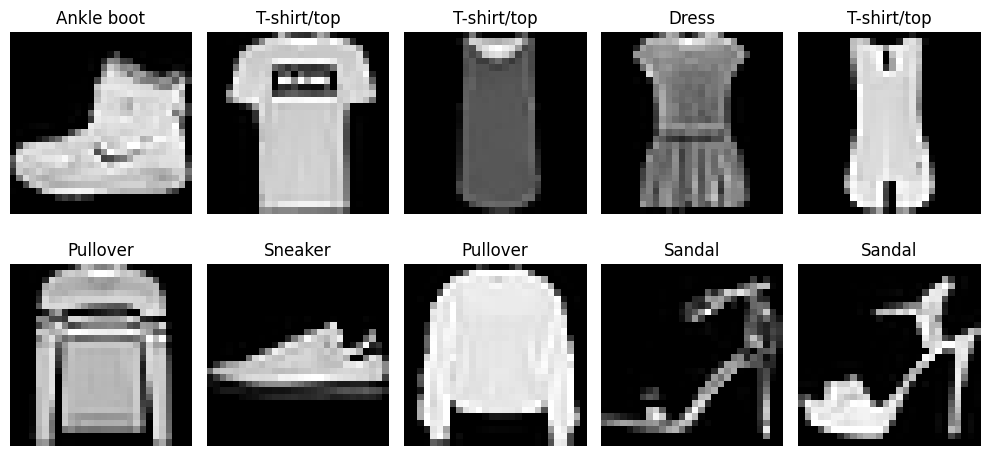

In [4]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

**Preprocessing gambar**

Normalisasi nilai piksel dari rentang 0–255 menjadi 0–1.

In [5]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

Tambahkan dimensi channel agar gambar memiliki format (28, 28, 1)

In [6]:
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


# **Modelling**

**Membangun model CNN**

In [7]:
def make_model():
  model = Sequential([
      Input(shape=(28, 28, 1)),
      Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same'),
      MaxPooling2D(pool_size=(2, 2)),
      Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'),
      MaxPooling2D(pool_size=(2, 2)),

      Flatten(),
      Dense(128, activation='relu'),
      Dense(10, activation='softmax')
      ])
  return model

tf.keras.utils.set_random_seed(123)
base_model = make_model()
initial_weights = base_model.get_weights()

**Training model**

In [17]:
optimizer_factories = {
    "SGD": lambda: keras.optimizers.SGD(learning_rate=0.01),
    "RMSprop": lambda: keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam": lambda: keras.optimizers.Adam(learning_rate=0.001)
}

histories = {}
results = []
model_weights = {}

for name, optimizer_factory in optimizer_factories.items():
    model = make_model()
    model.set_weights(initial_weights)
    model.compile(optimizer=optimizer_factory(),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    history = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=3,
        batch_size=128,
        verbose=1
    )
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    histories[name] = history.history
    model_weights[name] = model.get_weights()
    results.append((name, test_loss, test_acc))

Epoch 1/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 63s 163ms/step - accuracy: 0.5692 - loss: 1.3635 - val_accuracy: 0.7508 - val_loss: 0.7332
Epoch 2/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 69s 184ms/step - accuracy: 0.7449 - loss: 0.7107 - val_accuracy: 0.7896 - val_loss: 0.6032
Epoch 3/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 73s 161ms/step - accuracy: 0.7780 - loss: 0.6152 - val_accuracy: 0.8054 - val_loss: 0.5508
Epoch 1/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 61s 160ms/step - accuracy: 0.8034 - loss: 0.5395 - val_accuracy: 0.8767 - val_loss: 0.3462
Epoch 2/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 81s 158ms/step - accuracy: 0.8813 - loss: 0.3313 - val_accuracy: 0.8944 - val_loss: 0.2901
Epoch 3/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 59s 158ms/step - accuracy: 0.9001 - loss: 0.2760 - val_accuracy: 0.9037 - val_loss: 0.2667
Epoch 1/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 63s 165ms/step - accuracy: 0.8175 - loss: 0.5181 - val_accuracy: 0.8722 - val_loss: 0.3579
Epoch 2/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 80s 161ms/step - accuracy: 0.8827 - loss: 0.3322 - 

**Visualisasi learning curve**

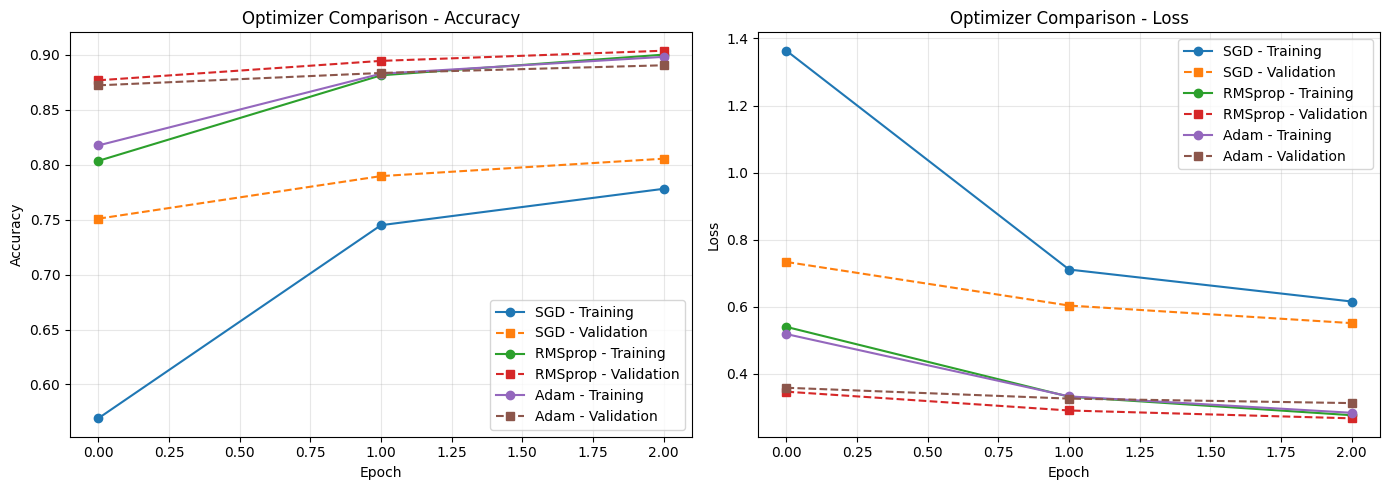

In [20]:
plt.figure(figsize=(14, 5))

# Panel 1: Accuracy
plt.subplot(1, 2, 1)

for name, history in histories.items():
    plt.plot(history['accuracy'], marker='o',
             label=f'{name} - Training')
    plt.plot(history['val_accuracy'], marker='s',
             linestyle='--', label=f'{name} - Validation')

plt.title('Optimizer Comparison - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)

# Panel 2: Loss
plt.subplot(1, 2, 2)

for name, history in histories.items():
    plt.plot(history['loss'], marker='o',
             label=f'{name} - Training')
    plt.plot(history['val_loss'], marker='s',
             linestyle='--', label=f'{name} - Validation')

plt.title('Optimizer Comparison - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# **Evaluasi**

In [21]:
best_model = make_model()

best_model.set_weights(model_weights["RMSprop"])

best_model.compile(
    optimizer=keras.optimizers.RMSprop(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [22]:
y_pred_prob = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)
print(classification_report(y_test, y_pred, target_names=class_names))

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.84      0.84      1000
     Trouser       0.98      0.99      0.98      1000
    Pullover       0.86      0.81      0.83      1000
       Dress       0.93      0.87      0.90      1000
        Coat       0.83      0.82      0.82      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.66      0.77      0.71      1000
     Sneaker       0.94      0.96      0.95      1000
         Bag       0.99      0.97      0.98      1000
  Ankle boot       0.97      0.96      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



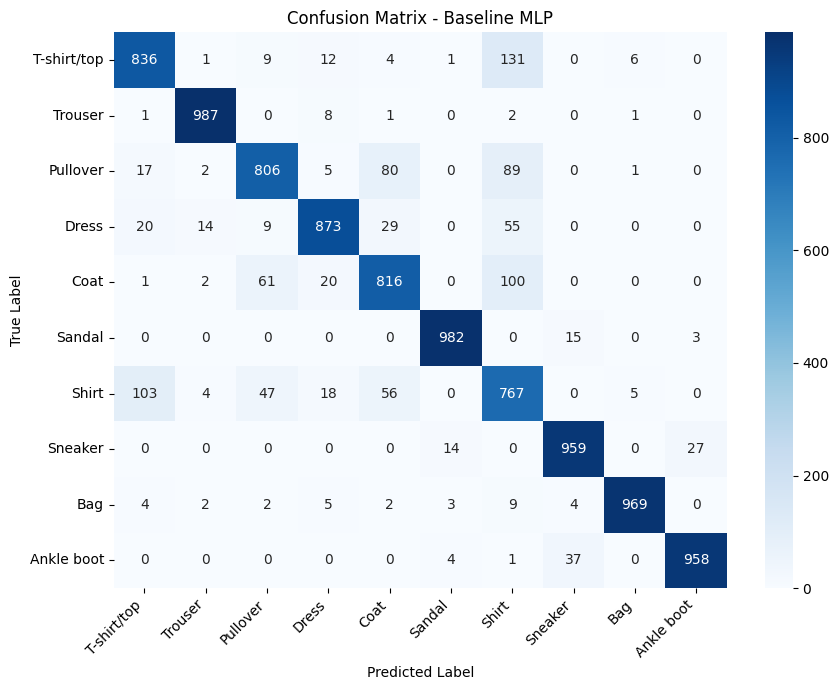

In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Baseline MLP")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()